<div style="background: linear-gradient(90deg, #0b3c5d 0%, #1d6fa3 60%, #5fb3d9 100%); padding: 28px 30px; border-radius: 10px; color: white;">
  <div style="font-size: 30px; font-weight: 700; letter-spacing: 1px;">🌊 ONDAS, OLEAJE Y NIVEL DEL MAR</div>
  <div style="font-size: 19px; margin-top: 6px; opacity: 0.95;">Propagación del oleaje con la ley de Snell entre dos puntos</div>
  <div style="font-size: 13px; margin-top: 14px; opacity: 0.85;">Geomatics and Ocean Engineering Group · E.T.S. Ingenieros de Caminos, Canales y Puertos · Universidad de Cantabria</div>
</div>

<p align="left">
  <img src="../images/Image_1.png" width="100">&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<img src="../images/Image_2.png" width="100">
</p>

### 📑 Contenido
1. Librerías
2. Datos de partida
3. Ecuaciones de la propagación
4. Paso a paso
5. La función `snell_propagation`
6. Propagación a varias profundidades
7. Propagación desde y hacia indefinidas

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 Antes de propagar series largas de oleaje o perfiles completos, vemos qué ocurre con <b>un único tren de ondas</b> que viaja entre <b>dos profundidades</b> sobre una batimetría recta y paralela: cómo cambian su longitud de onda, su celeridad, su dirección y su altura, y cómo lo calcula la función <code>snell_propagation</code> del curso.
</div>

---

## 1. Librerías

In [1]:
import os.path as op
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Funciones propias del curso (carpeta ../functions)
sys.path.append(op.abspath('..'))
from functions.snell_mono import *

pd.set_option('display.precision', 3)

---

## 2. Datos de partida

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>H_ini</code>: altura de ola en el punto inicial [m]</li>
<li><code>T</code>: periodo [s]</li>
<li><code>theta_ini</code>: ángulo del oleaje respecto a la normal a las batimétricas en el punto inicial [º]</li>
<li><code>h_ini</code>: profundidad del punto inicial [m]</li>
<li><code>h_fin</code>: profundidad del punto final [m]</li>
</ul>
</div>

In [11]:
H_ini = 2.0       # [m]
T = 10.0          # [s]
theta_ini = 30.0  # [º]

h_ini = 30.0      # [m]
h_fin = 5.0       # [m]

---

## 3. Ecuaciones de la propagación

Con batimetría recta y paralela, entre dos profundidades:

| Paso | Ecuación | Qué representa |
|---|---|---|
| Dispersión | $\omega^2 = gk\tanh(kh)$, $\; L = 2\pi/k$, $\; C = L/T$ | La onda se frena y se acorta al disminuir la profundidad (el periodo se conserva) |
| Celeridad de grupo | $C_g = nC$, $\; n = \frac{1}{2}\left(1 + \frac{2kh}{\sinh 2kh}\right)$ | Velocidad a la que viaja la energía |
| Ley de Snell | $\dfrac{\sin\theta_{fin}}{C_{fin}} = \dfrac{\sin\theta_{ini}}{C_{ini}}$ | **Refracción**: las crestas giran para ponerse paralelas a las batimétricas |
| Asomeramiento | $K_s = \sqrt{C_{g,ini}/C_{g,fin}}$ | Cambio de altura por el cambio de la velocidad de la energía |
| Refracción | $K_r = \sqrt{\cos\theta_{ini}/\cos\theta_{fin}}$ | Cambio de altura por la separación de los rayos |
| Altura de ola | $H_{fin} = H_{ini}\,K_s\,K_r$ | Conservación del flujo de energía entre rayos |

Hipótesis: teoría lineal (pequeña amplitud), oleaje monocromático, batimetría recta y paralela con pendiente suave,
sin disipación (fricción, rotura), sin difracción ni corrientes.

---

## 4. Paso a paso

### <span style='color:#1d6fa3'>4.1 Dispersión: longitud de onda y celeridad</span>

In [3]:
L_i, k_i, C_i = waves_dispersion(T, h_ini)
L_f, k_f, C_f = waves_dispersion(T, h_fin)
L0 = g * T**2 / (2 * np.pi)   # longitud de onda en indefinidas, como referencia


def regimen(h, L):
    'Profundidad relativa'
    if h / L > 1 / 2:
        return 'indefinidas'
    return 'someras' if h / L < 1 / 20 else 'intermedias'


for nombre, h, L, C in [('inicial', h_ini, L_i, C_i), ('final', h_fin, L_f, C_f)]:
    print(f'Punto {nombre}: h = {h:5.1f} m   L = {L:6.1f} m   C = {C:5.2f} m/s   h/L = {h / L:.3f} -> {regimen(h, L)}')
print(f'Referencia en indefinidas: L0 = {L0:.1f} m')

Punto inicial: h =  30.0 m   L =  137.3 m   C = 13.73 m/s   h/L = 0.219 -> intermedias
Punto final: h =   5.0 m   L =   67.7 m   C =  6.77 m/s   h/L = 0.074 -> intermedias
Referencia en indefinidas: L0 = 156.1 m


### <span style='color:#1d6fa3'>4.2 Celeridad de grupo</span>

In [4]:
Cg_i, Cg_f = cg(L_i, T, h_ini), cg(L_f, T, h_fin)
print(f'Punto inicial: n = {Cg_i / C_i:.3f}   Cg = {Cg_i:.2f} m/s')
print(f'Punto final:   n = {Cg_f / C_f:.3f}   Cg = {Cg_f:.2f} m/s')

Punto inicial: n = 0.677   Cg = 9.29 m/s
Punto final:   n = 0.935   Cg = 6.33 m/s


### <span style='color:#1d6fa3'>4.3 Ley de Snell: nueva dirección</span>

In [5]:
theta_f = theta(C_i, C_f, theta_ini)
print(f'sin θ_fin = C_fin / C_ini · sin θ_ini = {C_f / C_i:.3f} · {np.sin(np.radians(theta_ini)):.3f}'
      f' = {np.sin(np.radians(theta_f)):.3f}   ->   θ_fin = {theta_f:.1f}º')

sin θ_fin = C_fin / C_ini · sin θ_ini = 0.493 · 0.500 = 0.246   ->   θ_fin = 14.3º


### <span style='color:#1d6fa3'>4.4 Coeficientes de asomeramiento y refracción, y altura final</span>

In [6]:
Ks_if = Ks(Cg_i, Cg_f)
Kr_if = Kr(theta_ini, theta_f)
H_f = H_ini * Ks_if * Kr_if
print(f'Ks = √(Cg_ini / Cg_fin) = {Ks_if:.3f}')
print(f'Kr = √(cos θ_ini / cos θ_fin) = {Kr_if:.3f}')
print(f'H_fin = H_ini · Ks · Kr = {H_ini} · {Ks_if:.3f} · {Kr_if:.3f} = {H_f:.2f} m')

Ks = √(Cg_ini / Cg_fin) = 1.212
Kr = √(cos θ_ini / cos θ_fin) = 0.945
H_fin = H_ini · Ks · Kr = 2.0 · 1.212 · 0.945 = 2.29 m


In [7]:
pd.DataFrame({'h [m]': [h_ini, h_fin], 'L [m]': [L_i, L_f], 'C [m/s]': [C_i, C_f], 'n': [Cg_i / C_i, Cg_f / C_f],
              'Cg [m/s]': [Cg_i, Cg_f], 'θ [º]': [theta_ini, theta_f], 'H [m]': [H_ini, H_f]},
             index=['Inicial', 'Final'])

,h [m],L [m],C [m/s],n,Cg [m/s],θ [º],H [m]
Inicial,30.0,137.295,13.729,0.677,9.295,30.000,2.000
Final,5.0,67.680,6.768,0.935,6.327,14.269,2.292


---

## 5. La función snell_propagation

La función `snell_propagation(H_ini, T, theta_ini, h_ini, h_fin)` de `functions/snell_mono.py` hace exactamente los pasos anteriores:

| Input | Descripción |
|---|---|
| `H_ini` | Altura de ola en el punto inicial [m] |
| `T` | Periodo [s] (se conserva durante la propagación) |
| `theta_ini` | Ángulo del oleaje respecto a la normal a las batimétricas en el punto inicial [º] |
| `h_ini` | Profundidad del punto inicial [m] (`np.inf` para indefinidas) |
| `h_fin` | Profundidad del punto final [m] (un número o un array de profundidades) |

Devuelve la altura de ola `H_fin` [m] y el ángulo `theta_fin` [º] en el punto final.

In [8]:
H_fin, theta_fin = snell_propagation(H_ini,      # altura de ola en el punto inicial [m]
                                     T,          # periodo [s]
                                     theta_ini,  # ángulo respecto a la normal en el punto inicial [º]
                                     h_ini,      # profundidad inicial [m]
                                     h_fin)      # profundidad final [m]

print(f'snell_propagation:  H_fin = {H_fin:.3f} m,  θ_fin = {theta_fin:.2f}º')
print(f'Paso a paso:        H_fin = {H_f:.3f} m,  θ_fin = {theta_f:.2f}º')

snell_propagation:  H_fin = 2.292 m,  θ_fin = 14.27º
Paso a paso:        H_fin = 2.292 m,  θ_fin = 14.27º


---

## 6. Propagación a varias profundidades

Como `h_fin` puede ser un array, con una sola llamada propagamos a muchas profundidades a la vez:

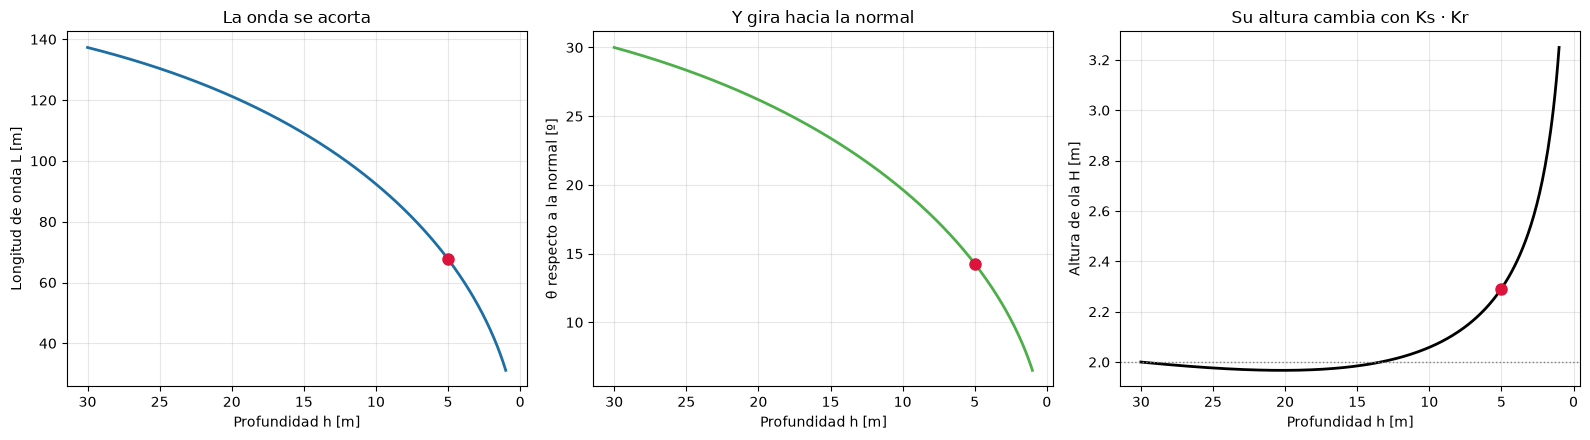

In [9]:
h_destino = np.linspace(h_ini, 1, 300)
H_dest, theta_dest = snell_propagation(H_ini, T, theta_ini, h_ini, h_destino)
L_dest, _, C_dest = waves_dispersion(T, h_destino)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(h_destino, L_dest, c='#1d6fa3', lw=2)
axs[0].set_ylabel('Longitud de onda L [m]')
axs[0].set_title('La onda se acorta')
axs[1].plot(h_destino, theta_dest, c='#4daf4a', lw=2)
axs[1].set_ylabel('θ respecto a la normal [º]')
axs[1].set_title('Y gira hacia la normal')
axs[2].plot(h_destino, H_dest, c='k', lw=2)
axs[2].axhline(H_ini, c='grey', ls=':', lw=1)
axs[2].set_ylabel('Altura de ola H [m]')
axs[2].set_title('Su altura cambia con Ks · Kr')
for ax in axs:
    ax.plot(h_fin, np.interp(h_fin, h_destino[::-1], ax.lines[0].get_ydata()[::-1]), 'o', c='crimson', ms=8)
    ax.invert_xaxis()   # mar adentro a la izquierda, costa a la derecha
    ax.set_xlabel('Profundidad h [m]')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 El punto rojo es el resultado de los apartados anteriores. Cerca de la orilla la altura crece mucho: la teoría lineal no incluye la rotura, que limita la altura de ola en profundidades pequeñas.
</div>

---

## 7. Propagación desde y hacia indefinidas

Las profundidades indefinidas se indican con `h = np.inf`. Además, las ecuaciones son **simétricas**: se puede propagar
hacia mar adentro intercambiando el punto inicial y el final, y se recupera el oleaje de partida.

In [10]:
# Hacia indefinidas desde el punto inicial
H_0, theta_0_ind = snell_propagation(H_ini, T, theta_ini, h_ini, np.inf)
print(f'En indefinidas:              H0 = {H_0:.3f} m,  θ0 = {theta_0_ind:.2f}º')

# Propagación inversa: del punto final al inicial
H_vuelta, theta_vuelta = snell_propagation(H_fin, T, theta_fin, h_fin, h_ini)
print(f'Inversa (h_fin -> h_ini):    H  = {H_vuelta:.3f} m,  θ  = {theta_vuelta:.2f}º   (datos: {H_ini} m, {theta_ini}º)')

En indefinidas:              H0 = 2.239 m,  θ0 = 34.65º
Inversa (h_fin -> h_ini):    H  = 2.000 m,  θ  = 30.00º   (datos: 2.0 m, 30.0º)


<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
🧪 Prueba a cambiar <code>theta_ini</code>, <code>T</code> o <code>h_fin</code> en la celda de INPUTS y vuelve a ejecutar
el notebook. ¿Qué ocurre si el oleaje llega con un ángulo muy oblicuo y lo propagas hacia indefinidas?
</div>